# Handwritten Digits Deep Learning
기존 `sklearn.load_digits()` 분류를 전통 ML 대신 신경망(DL)으로 수행한다.


In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

tf.random.set_seed(42)
np.random.seed(42)


In [2]:
digits = load_digits()

X = digits.data
y = digits.target

print("X shape:", X.shape)
print("y shape:", y.shape)
print("classes:", np.unique(y))


X shape: (1797, 64)
y shape: (1797,)
classes: [0 1 2 3 4 5 6 7 8 9]


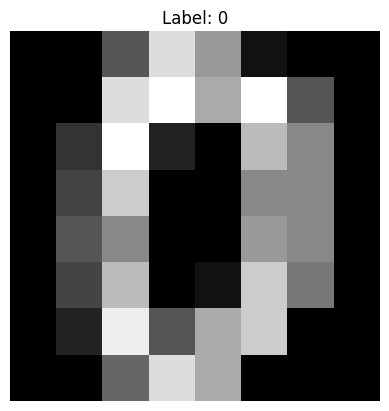

In [3]:
plt.imshow(digits.images[0], cmap="gray")
plt.title(f"Label: {y[0]}")
plt.axis("off")
plt.show()


픽셀값은 0~16이므로 16으로 나누어 0~1 범위로 정규화한다.
클래스는 0~9의 10개이며 One-hot encoding을 사용한다.


In [4]:
X = X / 16.0

y_onehot = tf.keras.utils.to_categorical(y, num_classes=10)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_onehot,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, y_train.shape)


(1437, 64) (1437, 10)


In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="sgd",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,226 (67.29 KB)

 Trainable params: 17,226 (67.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.1697 - loss: 2.2323 - val_accuracy: 0.2083 - val_loss: 2.1788
Epoch 2/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.2759 - loss: 2.1485 - val_accuracy: 0.3819 - val_loss: 2.1098
Epoch 3/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.4421 - loss: 2.0691 - val_accuracy: 0.4722 - val_loss: 2.0377
Epoch 4/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.5126 - loss: 1.9883 - val_accuracy: 0.5139 - val_loss: 1.9599
Epoch 5/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5692 - loss: 1.9032 - val_accuracy: 0.5799 - val_loss: 1.8759
Epoch 6/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6258 - loss: 1.8121 - val_accuracy: 0.6389 - val_loss: 1.7846
Epoch 7/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6832 - loss: 1.7143 - val_accuracy: 0.6840 - val_loss: 1.6863
Epoch 8/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7554 - loss: 1.6130 - val_accuracy: 0.7326 - val

In [7]:
y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

print("Accuracy =", accuracy_score(y_true, y_pred))
print("\nConfusion Matrix")
print(confusion_matrix(y_true, y_pred))
print("\nClassification Report")
print(classification_report(y_true, y_pred))


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Accuracy = 0.9138888888888889

Confusion Matrix
[[35  0  0  0  1  0  0  0  0  0]
 [ 0 27  2  0  0  1  2  0  1  3]
 [ 0  1 34  0  0  0  0  0  0  0]
 [ 0  0  1 34  0  0  0  2  0  0]
 [ 0  1  0  0 35  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  1  0 35  0  0  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  7  0  0  0  0  0  1 27  0]
 [ 0  0  0  2  0  0  0  4  1 29]]

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.75      0.75      0.75        36
           2       0.92      0.97      0.94        35
           3       0.94      0.92      0.93        37
           4       0.95      0.97      0.96        36
           5       0.97      1.00      0.99        37
           6       0.95      0.97      0.96        36
           7       0.84      1.00      0.91        36
           8       0.93      0.77      0.84        35
           9     

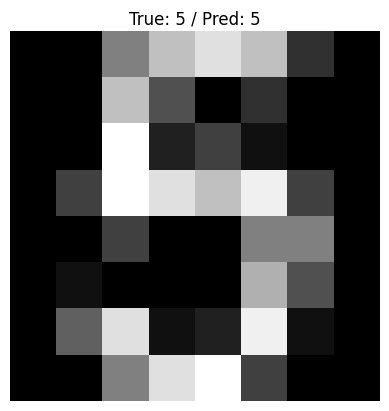

In [8]:
idx = 0
plt.imshow(X_test[idx].reshape(8, 8), cmap="gray")
plt.title(f"True: {y_true[idx]} / Pred: {y_pred[idx]}")
plt.axis("off")
plt.show()
